# Performance Analysis 

Dans ce notebook je vais importer les scores des différents scripts pour pouvoir choisir ceux qui vont inférer le dataset.

## Import Data

In [23]:
import glob
import numpy as np
import pandas as pd
from pathlib import Path

test_scores = glob.glob("src/transformation/evaluation_llm/test/*.csv")

df = pd.DataFrame()
for fichier in test_scores:
    temp_df = pd.read_csv(fichier)
    
    print(temp_df.head())
    
    df = pd.concat([df,temp_df])
    
df

        mode version  job_accuracy  job_macro_f1  job_nb_erreurs  \
0  Job_Stack      v1      0.512821      0.634127            19.0   

   required_precision  required_recall  required_f1  desired_precision  \
0            0.790698         0.459459     0.581197           0.085271   

   desired_recall  desired_f1  globale_precision  globale_recall  globale_f1  \
0        0.392857    0.140127           0.451163        0.551136    0.496164   

  status  erreur  
0     OK     NaN  
      mode version status  erreur  accuracy  nb_erreurs  nb_total
0  Company      v1     OK     NaN       1.0         0.0      35.0
    mode version  required_precision  required_recall  required_f1  \
0  Stack      v1            0.856115         0.804054     0.829268   
1  Stack      v2            0.780645         0.817568     0.798680   
2  Stack      v3            0.775510         0.770270     0.772881   

   desired_precision  desired_recall  desired_f1  globale_precision  \
0           0.348837        0.5

,mode,version,job_accuracy,job_macro_f1,job_nb_erreurs,required_precision,required_recall,required_f1,desired_precision,desired_recall,...,globale_f1,status,erreur,accuracy,nb_erreurs,nb_total,macro_f1,seniority_accuracy,seniority_macro_f1,seniority_nb_erreurs
0,Job_Stack,v1,0.512821,0.634127,19.0,0.790698,0.459459,0.581197,0.085271,0.392857,...,0.496164,OK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,Company,v1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,OK,NaN,1.000000,0.0,35.0,NaN,NaN,NaN,NaN
0,Stack,v1,NaN,NaN,NaN,0.856115,0.804054,0.829268,0.348837,0.535714,...,0.759777,OK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Stack,v2,NaN,NaN,NaN,0.780645,0.817568,0.798680,0.625000,0.535714,...,0.777465,OK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Stack,v3,NaN,NaN,NaN,0.775510,0.770270,0.772881,0.428571,0.535714,...,0.731844,OK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,Job,v1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,OK,NaN,0.820513,7.0,NaN,0.810830,NaN,NaN,NaN
1,Job,v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,OK,NaN,0.846154,6.0,NaN,0.833216,NaN,NaN,NaN
2,Job,v3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,OK,NaN,0.820513,7.0,NaN,0.813273,NaN,NaN,NaN
3,Job,v4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,OK,NaN,0.897436,4.0,NaN,0.895960,NaN,NaN,NaN
4,Job,v5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,OK,NaN,0.820513,7.0,NaN,0.829221,NaN,NaN,NaN


In [24]:

metrics = ["accuracy", "macro_f1", "nb_erreurs"]

# Normalise les colonnes pour comparer les performances des prompts sur chaque tache
for task in ["Job", "Seniority"]:
    mask = df["mode"].eq(task)

    for metric in metrics:
        source = metric
        target = f"{task.lower()}_{metric}"

        df.loc[mask, target] = df.loc[mask, source]

df_results = df.drop(
    columns=metrics,
    errors="ignore"
)

df_results


,mode,version,job_accuracy,job_macro_f1,job_nb_erreurs,required_precision,required_recall,required_f1,desired_precision,desired_recall,desired_f1,globale_precision,globale_recall,globale_f1,status,erreur,nb_total,seniority_accuracy,seniority_macro_f1,seniority_nb_erreurs
0,Job_Stack,v1,0.512821,0.634127,19.0,0.790698,0.459459,0.581197,0.085271,0.392857,0.140127,0.451163,0.551136,0.496164,OK,NaN,NaN,NaN,NaN,NaN
0,Company,v1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,35.0,NaN,NaN,NaN
0,Stack,v1,NaN,NaN,NaN,0.856115,0.804054,0.829268,0.348837,0.535714,0.422535,0.747253,0.772727,0.759777,OK,NaN,NaN,NaN,NaN,NaN
1,Stack,v2,NaN,NaN,NaN,0.780645,0.817568,0.798680,0.625000,0.535714,0.576923,0.770950,0.784091,0.777465,OK,NaN,NaN,NaN,NaN,NaN
2,Stack,v3,NaN,NaN,NaN,0.775510,0.770270,0.772881,0.428571,0.535714,0.476190,0.719780,0.744318,0.731844,OK,NaN,NaN,NaN,NaN,NaN
0,Job,v1,0.820513,0.810830,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,NaN,NaN,NaN,NaN
1,Job,v2,0.846154,0.833216,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,NaN,NaN,NaN,NaN
2,Job,v3,0.820513,0.813273,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,NaN,NaN,NaN,NaN
3,Job,v4,0.897436,0.895960,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,NaN,NaN,NaN,NaN
4,Job,v5,0.820513,0.829221,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,NaN,NaN,NaN,NaN


## Analysing performances according to task

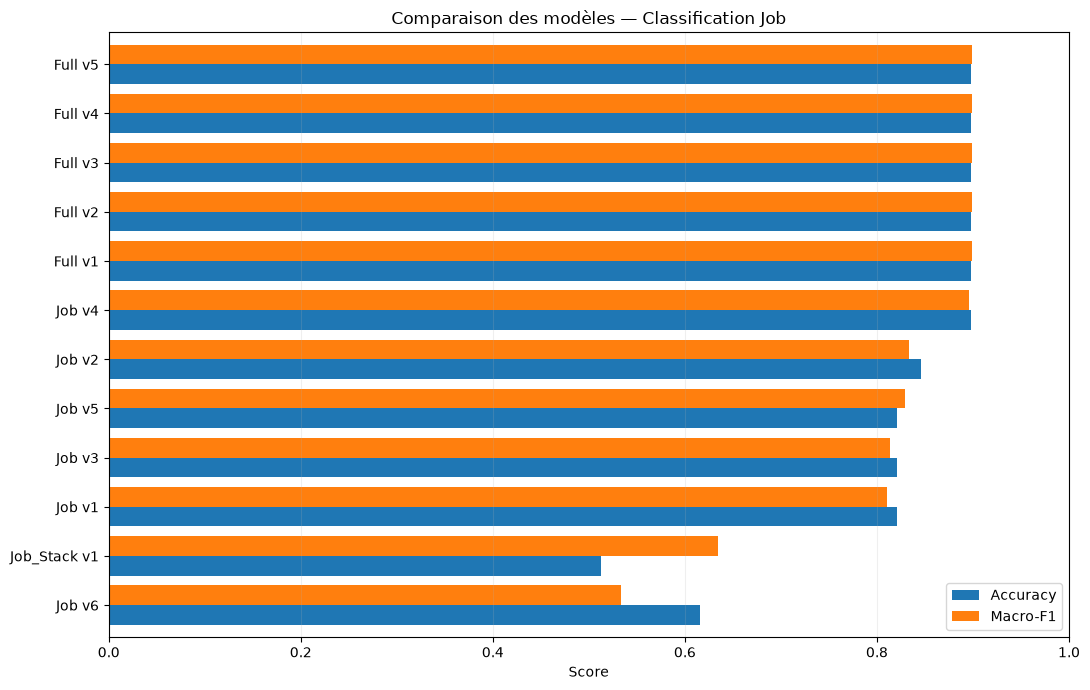

In [25]:

import matplotlib.pyplot as plt

job_df = df_results[
    df_results["mode"].isin(["Job", "Job_Stack", "Full"])
].copy()

job_df["model"] = job_df["mode"] + " " + job_df["version"]

job_df = job_df.sort_values("job_macro_f1")

ax = job_df.plot(
    x="model",
    y=["job_accuracy", "job_macro_f1"],
    kind="barh",
    figsize=(11, 7),
    width=0.8
)

ax.set_title("Comparaison des modèles — Classification Job")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["Accuracy", "Macro-F1"])
ax.grid(axis="x", alpha=0.2)
plt.savefig(Path("src/transformation/evaluation_llm/assets/job_results.png"))
plt.tight_layout()
plt.show()


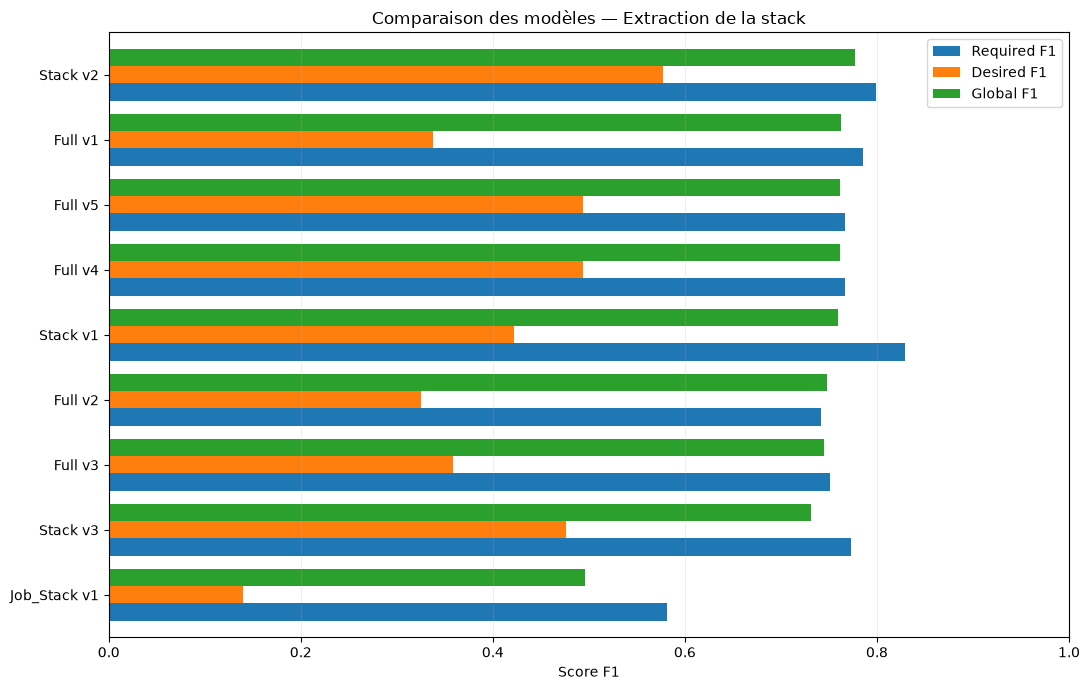

In [26]:

stack_df = df_results[df_results["mode"].isin(["Stack", "Job_Stack", "Full"])].copy()

stack_df["model"] = stack_df["mode"] + " " + stack_df["version"]

stack_df = stack_df.sort_values("globale_f1")

ax = stack_df.plot(x="model",y=["required_f1", "desired_f1", "globale_f1"],kind="barh",figsize=(11, 7),width=0.8)

ax.set_title("Comparaison des modèles — Extraction de la stack")
ax.set_xlabel("Score F1")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["Required F1", "Desired F1", "Global F1"])
ax.grid(axis="x", alpha=0.2)
plt.savefig(Path("src/transformation/evaluation_llm/assets/stack_results.png"))
plt.tight_layout()
plt.show()


Ici on peut voir que le score f1 global d'extraction de la stack pour le prompt full v5 est quasiment aussi bon que celui de Stack v2 et qu'il est aussi le meilleur pour l'inférence de la catégorie métier. Ainsi pour éviter de perdre trop de temps a utiliser les 3 meilleurs prompts, je vais simplement utiliser Full v5 pour les prédiction de catégorie d'emploi et d'extraction de stack.

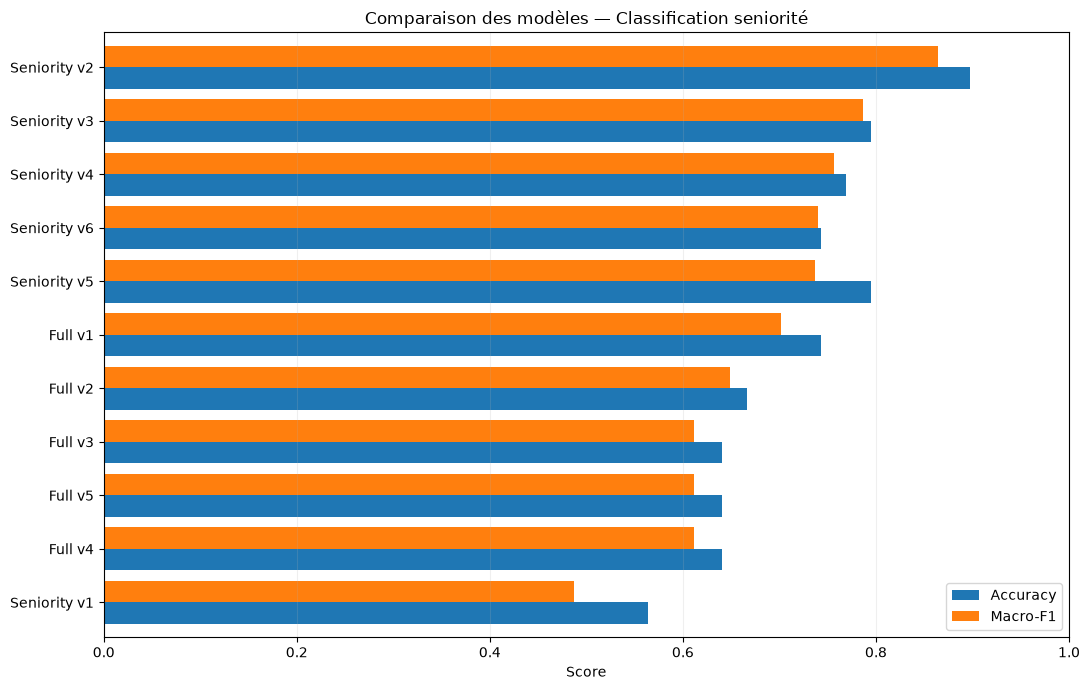

In [27]:

seniority_df = df_results[df_results["mode"].isin(["Seniority", "Full"])].copy()

seniority_df["model"] = (seniority_df["mode"] + " " + seniority_df["version"])

seniority_df = seniority_df.sort_values("seniority_macro_f1")

ax = seniority_df.plot(
    x="model",
    y=["seniority_accuracy", "seniority_macro_f1"],
    kind="barh",
    figsize=(11, 7),
    width=0.8
)

ax.set_title("Comparaison des modèles — Classification seniorité")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(["Accuracy", "Macro-F1"])
ax.grid(axis="x", alpha=0.2)
plt.savefig(Path("src/transformation/evaluation_llm/assets/seniortity_results.png"))
plt.tight_layout()
plt.show()


Ici le meilleur prompt est Seniority v2

### Standartisation company

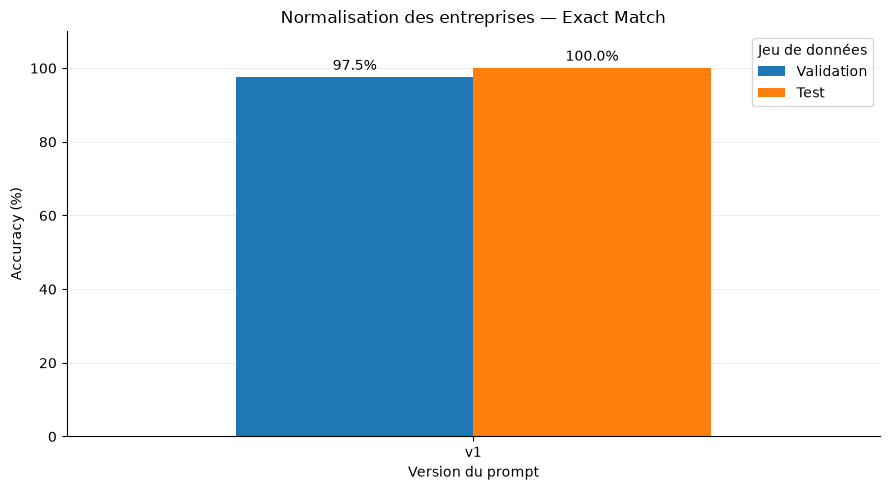

In [30]:
# Comparer les scores Company déjà calculés sur validation et test.
company_scores = []

for split in ["val", "test"]:
    path = Path("src/transformation/evaluation_llm") / split / f"results_{split}_company.csv"
    if not path.exists():
        raise FileNotFoundError(f"Fichier de scores manquant : {path}")

    scores = pd.read_csv(path)
    scores = scores.loc[scores["status"].eq("OK")].copy() if "status" in scores.columns else scores.copy()
    scores["dataset"] = "Validation" if split == "val" else "Test"
    company_scores.append(scores)

company_df = pd.concat(company_scores, ignore_index=True)
if company_df.empty:
    raise ValueError("Aucun score Company valide trouvé dans les fichiers CSV.")

# Une barre par jeu de données et par version du prompt.
accuracy_comparison = company_df.pivot_table(
    index="version", columns="dataset", values="accuracy", aggfunc="first"
)
accuracy_comparison = accuracy_comparison.reindex(columns=["Validation", "Test"])
accuracy_comparison = accuracy_comparison.sort_index(
    key=lambda s: s.str.extract(r"v(\d+)")[0].astype(int)
)

ax = accuracy_comparison.mul(100).plot(
    kind="bar", figsize=(9, 5), width=0.7, rot=0
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Normalisation des entreprises — Exact Match")
ax.set_xlabel("Version du prompt")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 110)
ax.legend(title="Jeu de données")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

assets_dir = Path("src/transformation/evaluation_llm/assets")
assets_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(assets_dir / "company_results.png", bbox_inches="tight")
plt.show()

In [31]:

tasks = {
    "Job": ("job_macro_f1", ["Job", "Job_Stack", "Full"]),
    "Seniority": (
        "seniority_macro_f1",
        ["Seniority", "Full"]
    ),
    "Stack required": (
        "required_f1",
        ["Stack", "Job_Stack", "Full"]
    ),
    "Stack desired": (
        "desired_f1",
        ["Stack", "Job_Stack", "Full"]
    ),
    "Stack globale": (
        "globale_f1",
        ["Stack", "Job_Stack", "Full"]
    ),
}
df_results = df_results.reset_index(drop=True)

best_models = []

for task, (metric, modes) in tasks.items():
    subset = df_results[
        df_results["mode"].isin(modes)
    ].dropna(subset=[metric])

    if subset.empty:
        continue

    best = subset.loc[subset[metric].idxmax()] 

    best_models.append({
        "Tâche": task,
        "Mode": best["mode"],
        "Version": best["version"],
        "Métrique": metric,
        "Score": best[metric]
    })

best_models_df = pd.DataFrame(best_models)

best_models_df


,Tâche,Mode,Version,Métrique,Score
0,Job,Full,v1,job_macro_f1,0.898656
1,Seniority,Seniority,v2,seniority_macro_f1,0.864583
2,Stack required,Stack,v1,required_f1,0.829268
3,Stack desired,Stack,v2,desired_f1,0.576923
4,Stack globale,Stack,v2,globale_f1,0.777465
